**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

**Student Name:** Sahra Yalçın

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

Confusion matrix is
[[  0 139   7]
 [  0   7  61]
 [119   0   0]]
Adjusted rand score is
0.890036904672631


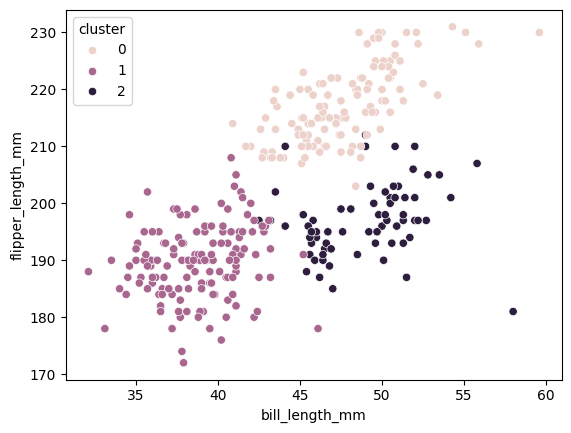

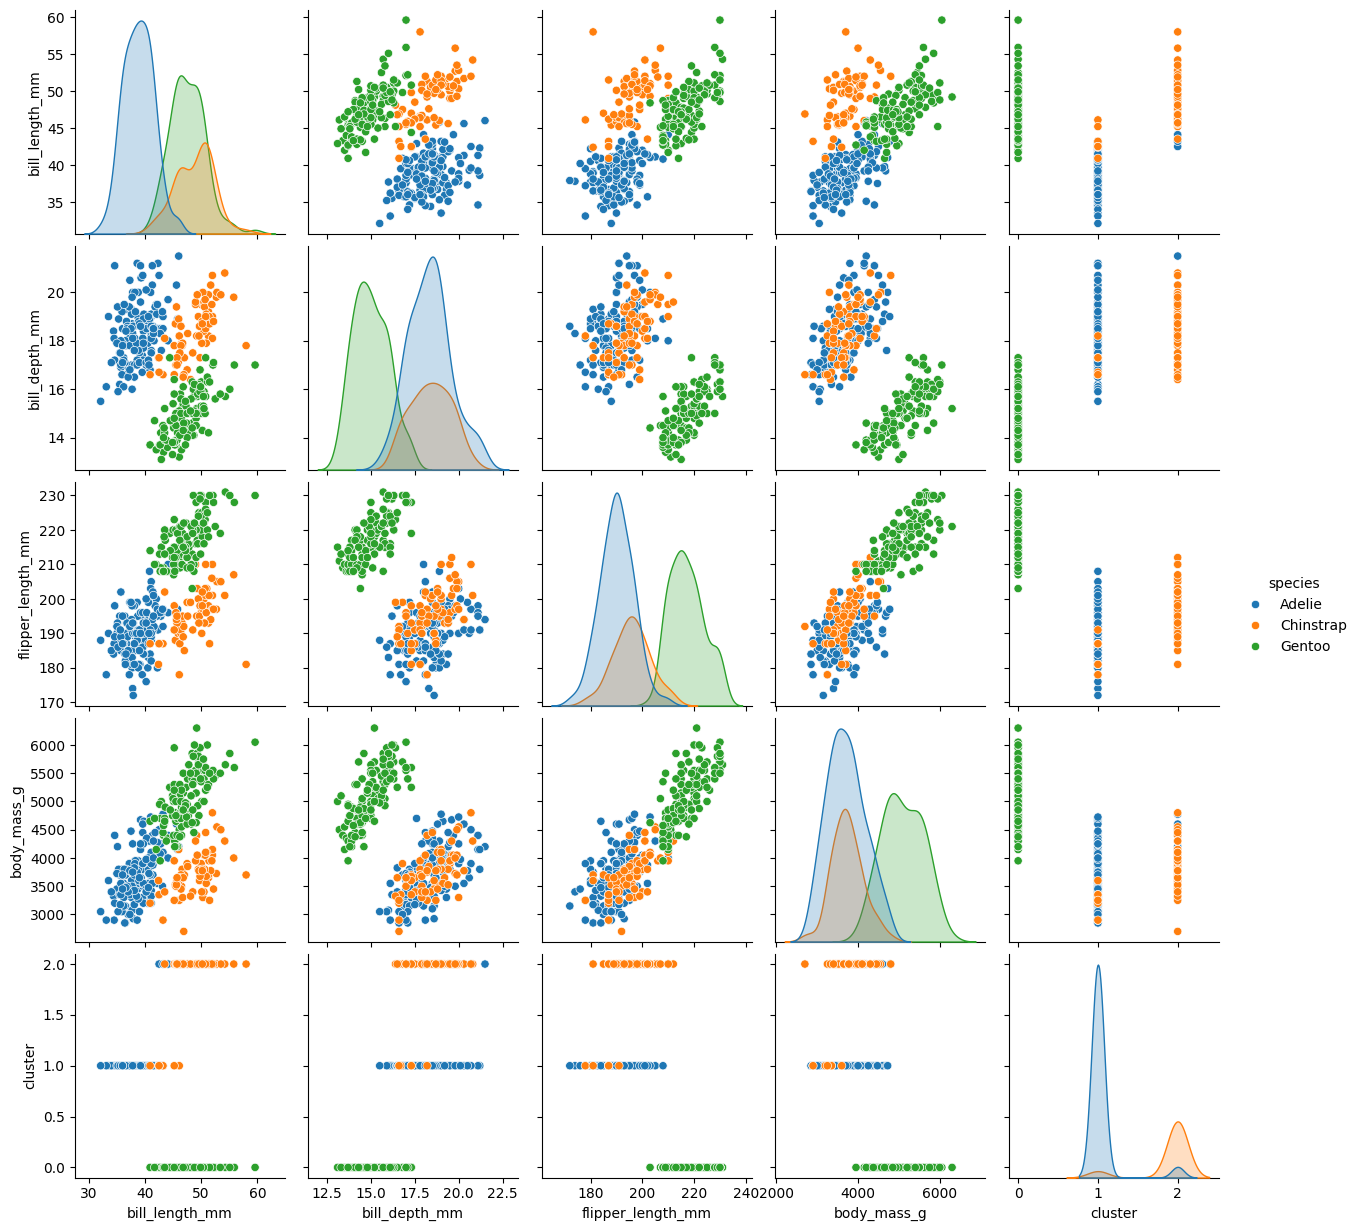

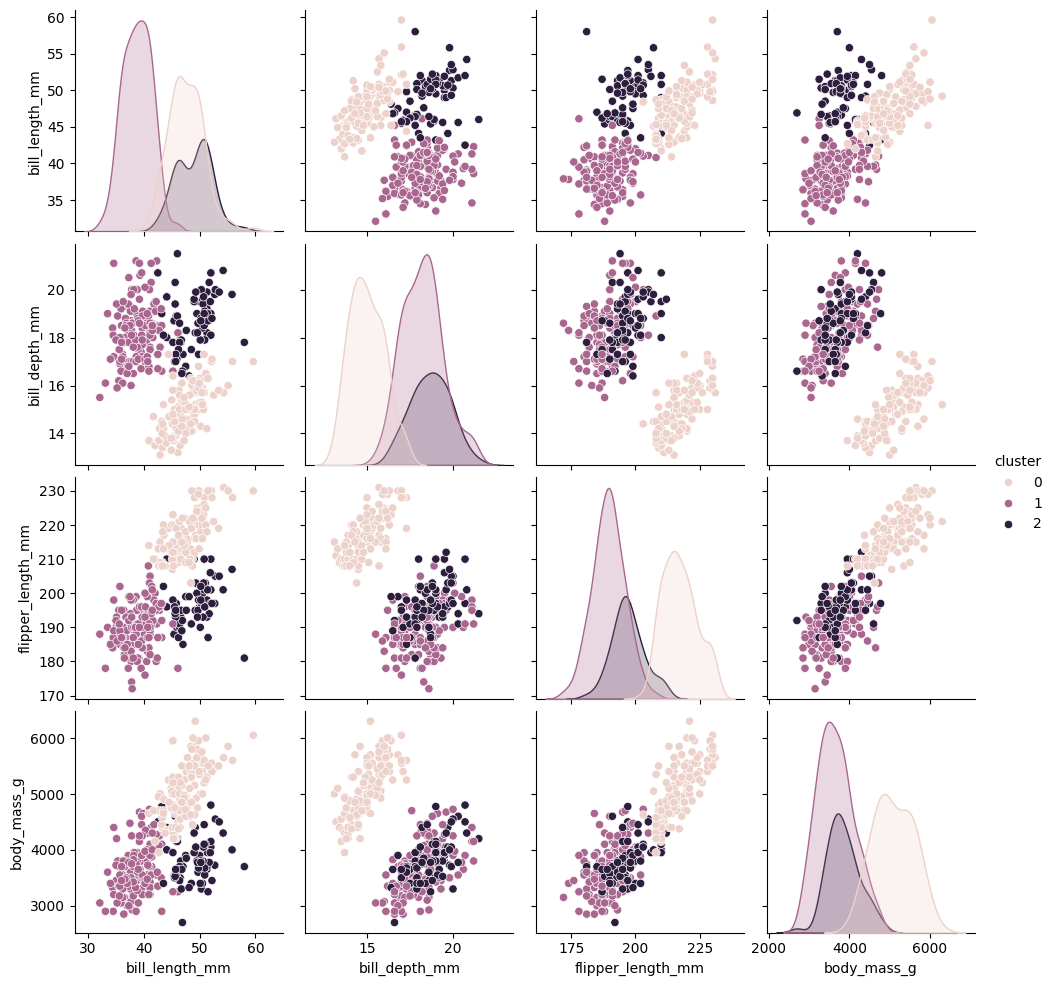

In [6]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# a) YOUR CODE HERE: check missing values per column, then dropna() and confirm the data is clean

penguins.isna().sum() #this shows the amount of missing values for each column

penguins_clean = penguins.dropna().copy() #penguins_clean is to be removed of rows with missing values

penguins_clean.isna().sum() #checking if the penguins_clean is clean of empty data


# b) YOUR CODE HERE: normalize the numeric columns with StandardScaler

penguins_scaled_df = pd.DataFrame(StandardScaler().fit_transform(penguins_clean[num_cols]), columns=num_cols)


# c) YOUR CODE HERE: apply KMeans with n_clusters=3 on the normalized data

kmeans = KMeans(n_clusters=3)
kmeans_labels = kmeans.fit_predict(penguins_scaled_df)

# d) YOUR CODE HERE: add kmeans_labels to penguins_clean, plot bill_length_mm vs flipper_length_mm colored by cluster,
#    and make two pairplots (one hue='species', one hue=kmeans cluster)

penguins_clean['cluster'] = kmeans_labels #add kmeans_labels to penguins_clean part

sns.scatterplot(data=penguins_clean, x='bill_length_mm', y='flipper_length_mm', hue='cluster') #plotting part

#two pairplots:

sns.pairplot(penguins_clean, hue='species')
sns.pairplot(penguins_clean, hue='cluster')

# e) YOUR CODE HERE: confusion matrix and adjusted Rand score vs real 'species'

species_labels = LabelEncoder().fit_transform(penguins_clean['species'])

confusionm = confusion_matrix(species_labels, kmeans_labels)
print("Confusion matrix is")
print(confusionm)

adjrand = adjusted_rand_score(species_labels, kmeans_labels)
print("Adjusted rand score is")
print(adjrand)

# f) YOUR CODE HERE (as a comment or markdown cell): interpretation

#interpretation is below in a markdown cell



**INTERPRETATION**

We used a K-means algorithm to set the penguins into 3 clusters based on their data. Then, we compared these clusters with the actual assigned penguin species.
Steps on how we did that:
First, we cleaned the data by removing the ones with missing values. Then  we normalized the columns which allowed us to do the clustering. Next, we used K-means algorithm to divide the penguins into 3 clusters.

To see how well the K-means performed, we can look at the Adjusted Rand Score. The Adjusted Rand Score measures how well the clusters match the real groups. The closer the ARI score is to 1, the better match it is. Our ARI was 0.7994, which means the clustering is very accurate. Looking at the plots, we can see that Gentoo penguins were separated more clearly, but in some aspects Adelie and Chinstrap penguins were mixed.

---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

Is there any missing? : False
5.656854249492381
5.656854249492381


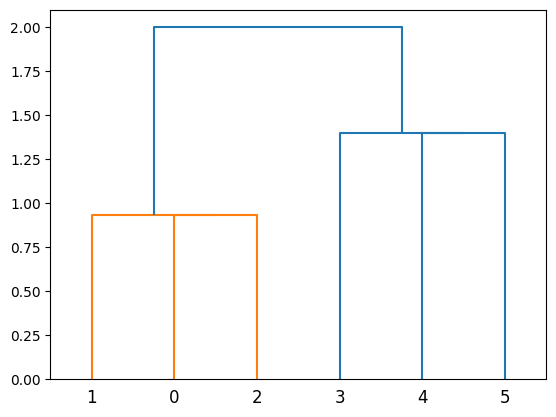

Agglomerative: [1 1 1 0 0 0]
K-means: [1 1 1 0 0 0]


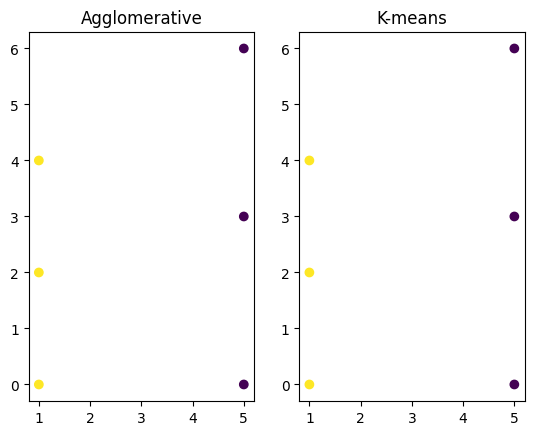

{np.int64(1): 3, np.int64(0): 3}
{np.int32(1): 3, np.int32(0): 3}


In [13]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) YOUR CODE HERE: check for missing values with np.isnan(X).any()

print("Is there any missing? :", np.isnan(X).any())

# b) YOUR CODE HERE: normalize X with StandardScaler

X_scaled = StandardScaler().fit_transform(X)

# c) YOUR CODE HERE: plain-Python euclidean_distance function using a for loop (no numpy/sklearn)
def euclidean_distance(p1, p2):
    total = 0
    for i in range(len(p1)):
        total += (p1[i] - p2[i])**2
    return total**0.5

# test it
print(euclidean_distance(X[0], X[3]))
print(np.linalg.norm(X[0] - X[3]))

# d) YOUR CODE HERE: agglomerative clustering on X_scaled + dendrogram

agglo = AgglomerativeClustering(n_clusters=2)
agglo_labels = agglo.fit_predict(X_scaled)

dendrogram(linkage(X_scaled)) #it was already imported
plt.show()

# e) YOUR CODE HERE: k-means clustering with n_clusters=2 on X_scaled

kmeans = KMeans(n_clusters=2)
kmeans_labels = kmeans.fit_predict(X_scaled)

# f) YOUR CODE HERE: compare both label arrays and make a side-by-side scatterplot
print("Agglomerative:", agglo_labels)
print("K-means:", kmeans_labels)

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=agglo_labels)
plt.title("Agglomerative")

plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=kmeans_labels)
plt.title("K-means")

plt.show()

# g) YOUR CODE HERE: cluster_sizes function using a dictionary
def cluster_sizes(labels):
    counts = {}
    for label in labels:
        if label in counts:
            counts[label] += 1
        else:
            counts[label] = 1
    return counts

print(cluster_sizes(agglo_labels))
print(cluster_sizes(kmeans_labels))


---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

carat    0
depth    0
table    0
price    0
dtype: int64
carat    0
depth    0
table    0
price    0
dtype: int64


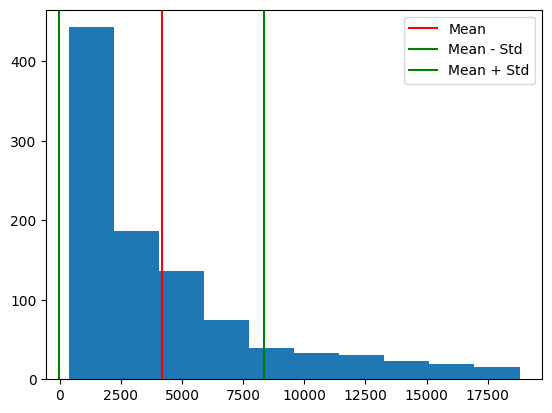

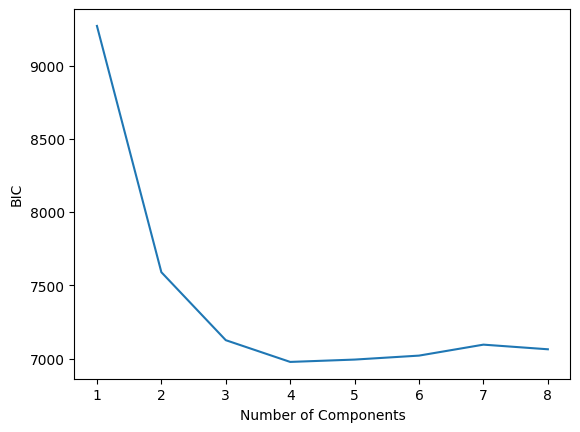

Best number of components: 4


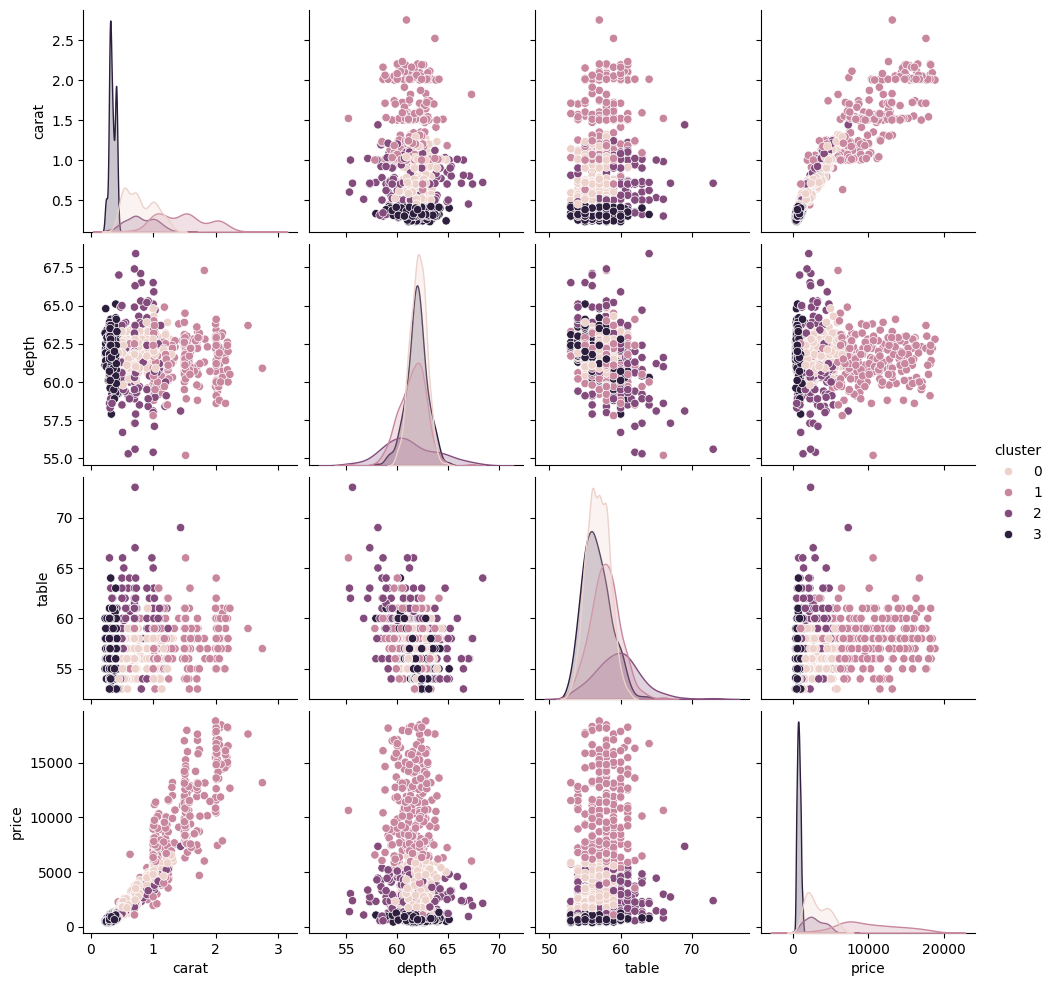

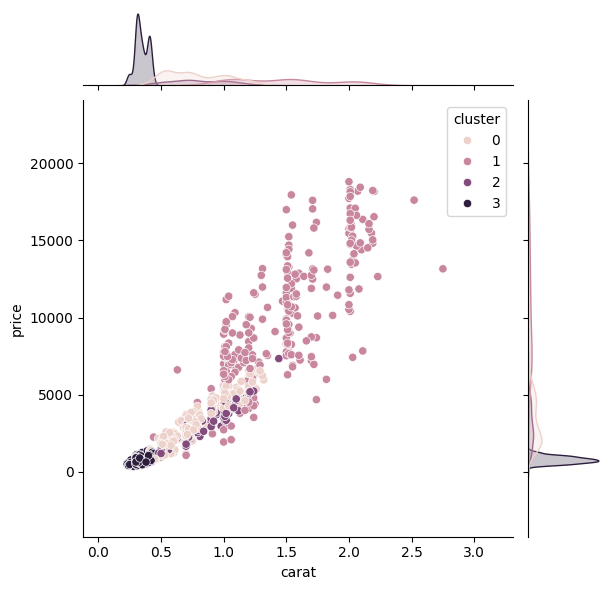

In [16]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) YOUR CODE HERE: select numeric columns into diamonds_num, check missing values, dropna() and confirm it's clean
diamonds_num = diamonds[['carat', 'depth', 'table', 'price']] #making a new dataset with asked columns

print(diamonds_num.isna().sum())

diamonds_num = diamonds_num.dropna().copy()

print(diamonds_num.isna().sum())

# b) YOUR CODE HERE: histogram of 'price' with mean and mean +/- std lines

mean_price = diamonds_num['price'].mean() #calculates mean price
std_price = diamonds_num['price'].std() #calculates standard price

plt.hist(diamonds_num['price'])

plt.axvline(mean_price, color='red', label='Mean') #shows mean price on plot

#for the +/-std lines:
plt.axvline(mean_price - std_price, color='green', label='Mean - Std')
plt.axvline(mean_price + std_price, color='green', label='Mean + Std')

plt.legend()
plt.show()


# c) YOUR CODE HERE: normalize the 4 numeric columns with StandardScaler
diamonds_scaled = StandardScaler().fit_transform(diamonds_num)

# d) YOUR CODE HERE: fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components
bic = []
n_components_range = range(1, 9)

for n in n_components_range:
    gmm = mixture.GaussianMixture(n_components=n)
    gmm.fit(diamonds_scaled)
    bic.append(gmm.bic(diamonds_scaled))

plt.plot(n_components_range, bic)
plt.xlabel('Number of Components')
plt.ylabel('BIC')
plt.show()


# e) YOUR CODE HERE: find the number of components that minimizes BIC and fit the final GMM

#We selected the number of components with the lowest bic
# Then, we used it to build the GMM model and to group the diamonds into clusters


best_n = n_components_range[np.argmin(bic)]

gmm = mixture.GaussianMixture(n_components=best_n)
gmm_labels = gmm.fit_predict(diamonds_scaled)

print("Best number of components:", best_n)


# f) YOUR CODE HERE: add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)

diamonds_num['cluster'] = gmm_labels
sns.pairplot(diamonds_num, vars=['carat', 'depth', 'table', 'price'], hue='cluster')
sns.jointplot(data=diamonds_num, x='carat', y='price', hue='cluster')


# g) YOUR CODE HERE (as a comment or markdown cell): interpretation
#INTERPRETATION BELOW


**INTERPRETATION**

We started by cleaning dataset and normalizing the columns. After that, we applied GMM with different numbers of components and calculated the BIC values.
Low BIC is better so we selected 4 components, which had the lowest BIC. Finally, we visualized the 4 clusters. The clusters show differences especially about carats and price. However, some overlap exists between the clusters.

However, looking at the plots visually, I think 4 clusters are more than what is needed because some groups cannot be differentiated. I would expect 2 clusters. We don't know if normalization changed the number of clusters because we didn't test the data without normalization.
